# Plant Disease Prediction

## Importing Dataset

Dataset Link: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
print(tf.config.list_physical_devices('GPU'))

NameError: name 'tf' is not defined

In [8]:
training_set = tf.keras.utils.image_dataset_from_directory(
    'train',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 70295 files belonging to 38 classes.


In [9]:
!nvidia-smi

Fri Feb 20 12:23:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.74                 Driver Version: 591.74         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   42C    P0             15W /   94W |       0MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

NameError: name 'tf' is not defined

In [8]:
cnn = tf.keras.models.Sequential()

NameError: name 'tf' is not defined

In [12]:
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [13]:
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [14]:
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [15]:
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [16]:
cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

In [17]:
cnn.add(tf.keras.layers.Dropout(0.25))

In [18]:
cnn.add(tf.keras.layers.Flatten())

In [19]:
cnn.add(tf.keras.layers.Dense(units=1500,activation='relu'))

In [20]:
cnn.add(tf.keras.layers.Dropout(0.4)) #To avoid overfitting

In [21]:
#Output Layer
cnn.add(tf.keras.layers.Dense(units=38,activation='softmax'))

In [22]:
cnn.compile(optimizer=tf.keras.optimizers.legacy.Adam(
    learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [7]:
cnn.summary()

NameError: name 'cnn' is not defined

In [6]:
training_history = cnn.fit(x=training_set,validation_data=validation_set,epochs=10)

NameError: name 'cnn' is not defined

## Evaluating Model

In [ ]:
#Training set Accuracy
train_loss, train_acc = cnn.evaluate(training_set)
print('Training accuracy:', train_acc)

2197/2197 [==============================] - 68s 31ms/step - loss: 0.0337 - accuracy: 0.9887
Training accuracy: 0.9886904954910278


In [ ]:
#Validation set Accuracy
val_loss, val_acc = cnn.evaluate(validation_set)
print('Validation accuracy:', val_acc)

196/196 [==============================] - 6s 28ms/step - loss: 0.1461 - accuracy: 0.9576
Validation accuracy: 0.9575728178024292


### Saving Model

In [ ]:
cnn.save('trained_plant_disease_model.keras')

In [ ]:
training_history.history #Return Dictionary of history

{'loss': [1.4111075401306152,
  0.4642287492752075,
  0.27090153098106384,
  0.1873461902141571,
  0.13931028544902802,
  0.10979680716991425,
  0.08910805732011795,
  0.0775984600186348,
  0.06230718269944191,
  0.056483883410692215],
 'accuracy': [0.5848780274391174,
  0.8531190156936646,
  0.912497341632843,
  0.9387438893318176,
  0.9547194242477417,
  0.9638096690177917,
  0.9708940982818604,
  0.9744789600372314,
  0.9794011116027832,
  0.9814069271087646],
 'val_loss': [0.5088686943054199,
  0.29483455419540405,
  0.28512871265411377,
  0.1835310310125351,
  0.29139888286590576,
  0.1480550616979599,
  0.0987328365445137,
  0.10314181447029114,
  0.09720548242330551,
  0.1460765302181244],
 'val_accuracy': [0.8301312923431396,
  0.9008965492248535,
  0.9047390222549438,
  0.9412423968315125,
  0.9069804549217224,
  0.9551712870597839,
  0.9711815714836121,
  0.9673390984535217,
  0.9692603349685669,
  0.9575728178024292]}

In [ ]:
#Recording History in json
import json
with open('training_hist.json','w') as f:
  json.dump(training_history.history,f)

In [ ]:
print(training_history.history.keys())

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


## Accuracy Visualization

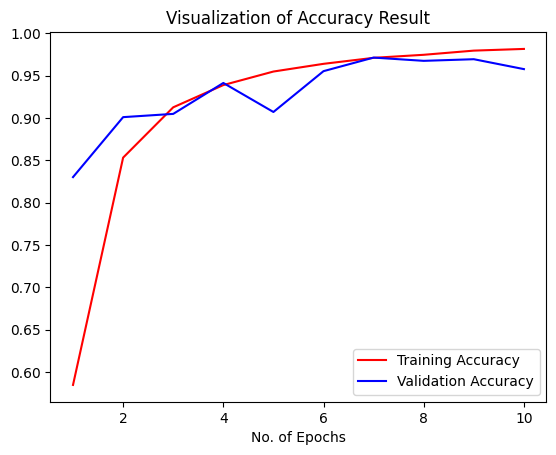

In [ ]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='red',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='blue',label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show()

## Some other metrics for model evaluation

In [ ]:
class_name = validation_set.class_names

In [ ]:
test_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=1,
    image_size=(128, 128),
    shuffle=False,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 17572 files belonging to 38 classes.


In [ ]:
y_pred = cnn.predict(test_set)
predicted_categories = tf.argmax(y_pred, axis=1)

17572/17572 [==============================] - 168s 9ms/step


In [ ]:
true_categories = tf.concat([y for x, y in test_set], axis=0)
Y_true = tf.argmax(true_categories, axis=1)

In [ ]:
Y_true

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], dtype=int64)>

In [ ]:
predicted_categories

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], dtype=int64)>

In [ ]:
from sklearn.metrics import confusion_matrix,classification_report
cm = confusion_matrix(Y_true,predicted_categories)

In [ ]:
# Precision Recall Fscore
print(classification_report(Y_true,predicted_categories,target_names=class_name))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.96      0.96      0.96       504
                                 Apple___Black_rot       0.98      0.98      0.98       497
                          Apple___Cedar_apple_rust       0.96      0.97      0.97       440
                                   Apple___healthy       0.95      0.96      0.96       502
                               Blueberry___healthy       0.93      0.99      0.96       454
          Cherry_(including_sour)___Powdery_mildew       0.99      0.99      0.99       421
                 Cherry_(including_sour)___healthy       0.99      0.96      0.97       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.87      0.95      0.91       410
                       Corn_(maize)___Common_rust_       0.99      0.99      0.99       477
               Corn_(maize)___Northern_Leaf_Blight       0.95      0.93      0.

### Confusion Matrix Visualization

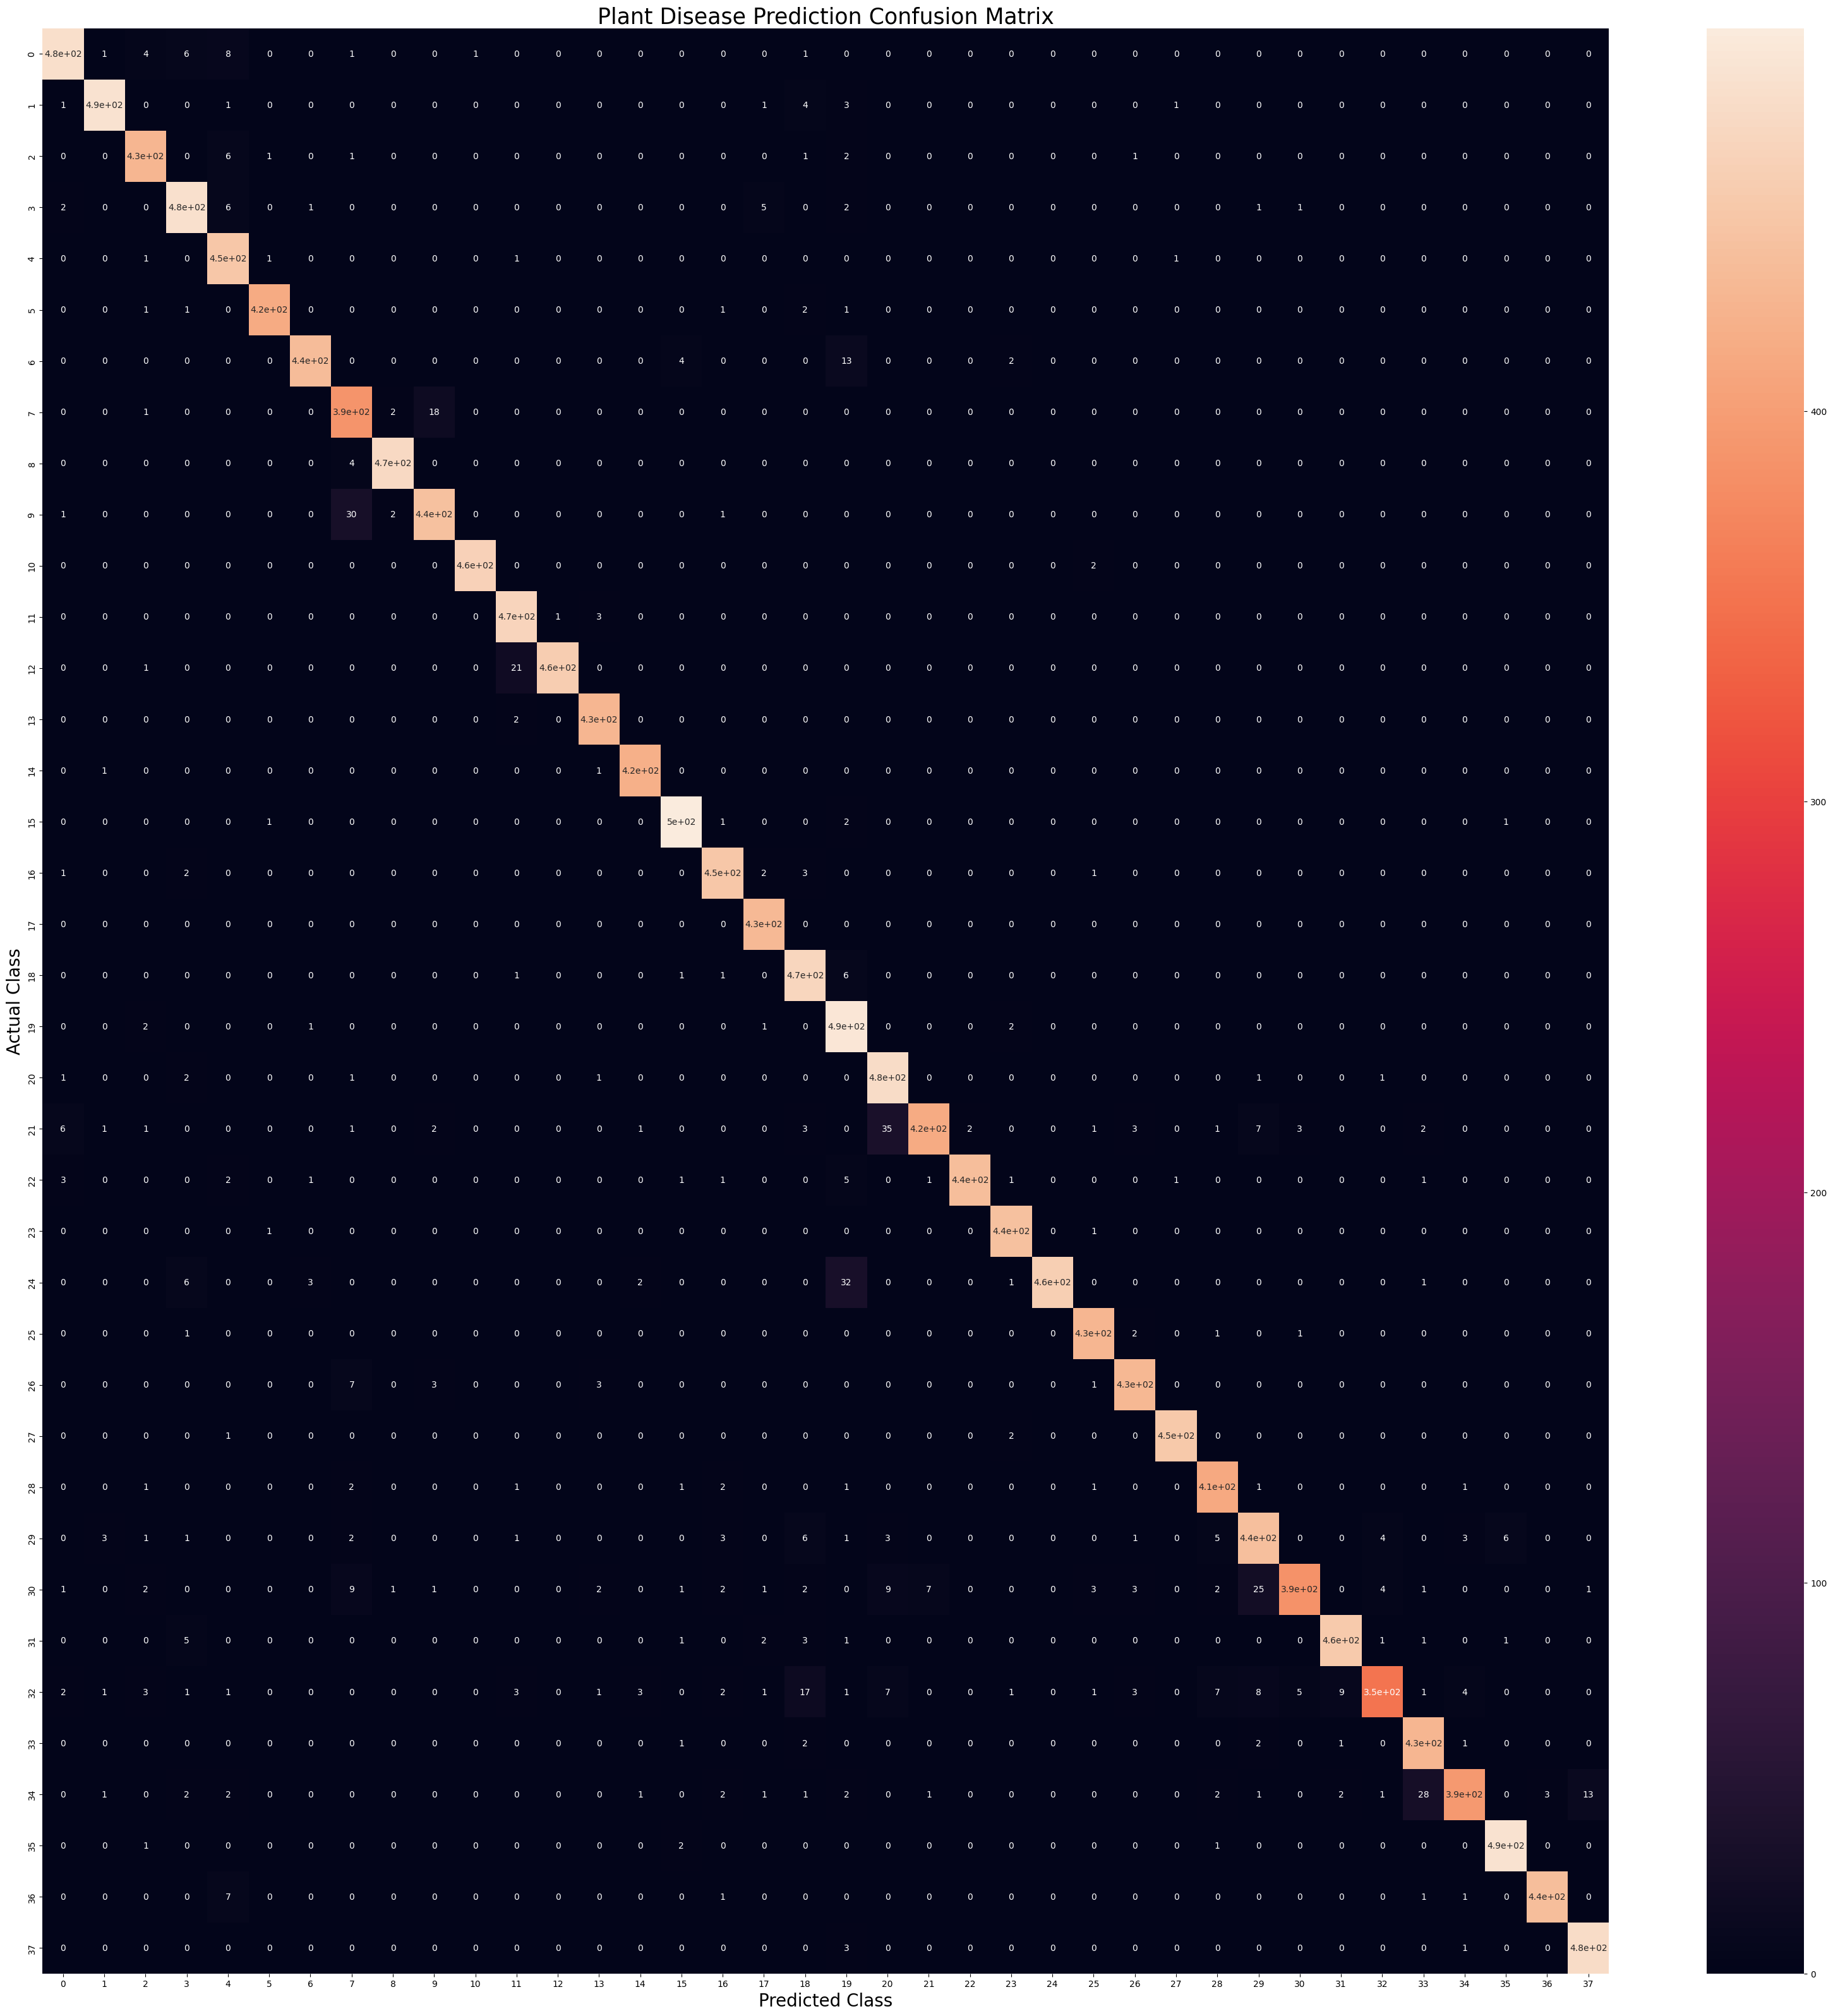

In [ ]:
plt.figure(figsize=(40, 40))
sns.heatmap(cm,annot=True,annot_kws={"size": 10})

plt.xlabel('Predicted Class',fontsize = 20)
plt.ylabel('Actual Class',fontsize = 20)
plt.title('Plant Disease Prediction Confusion Matrix',fontsize = 25)
plt.show()

In [4]:
# %% Setup (run this first)
import numpy as np
import tensorflow as tf

validation_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(128, 128),
    shuffle=False  # keep fixed order for metrics/graphs
)

class_names = validation_set.class_names
print(class_names)


Found 17572 files belonging to 38 classes.
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Tw

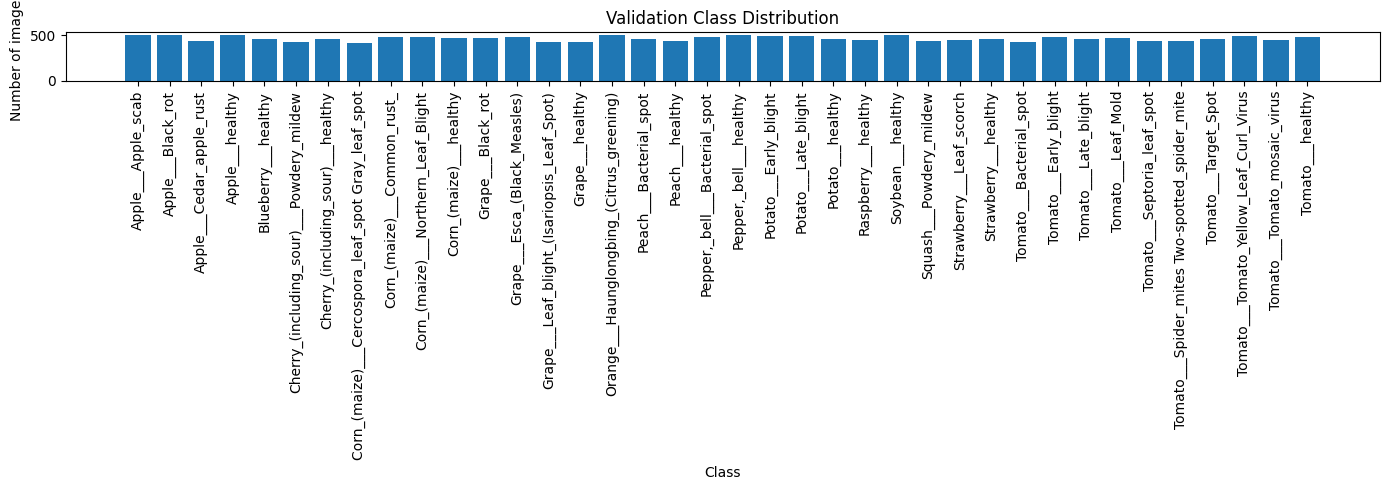

In [5]:
# %% 1) Class distribution in validation set
class_names = validation_set.class_names

y_true_all = []
for _, labels in validation_set:
    y_true_all.extend(np.argmax(labels.numpy(), axis=1))
y_true_all = np.array(y_true_all)

counts = np.bincount(y_true_all, minlength=len(class_names))

plt.figure(figsize=(14,5))
plt.bar(class_names, counts)
plt.title("Validation Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


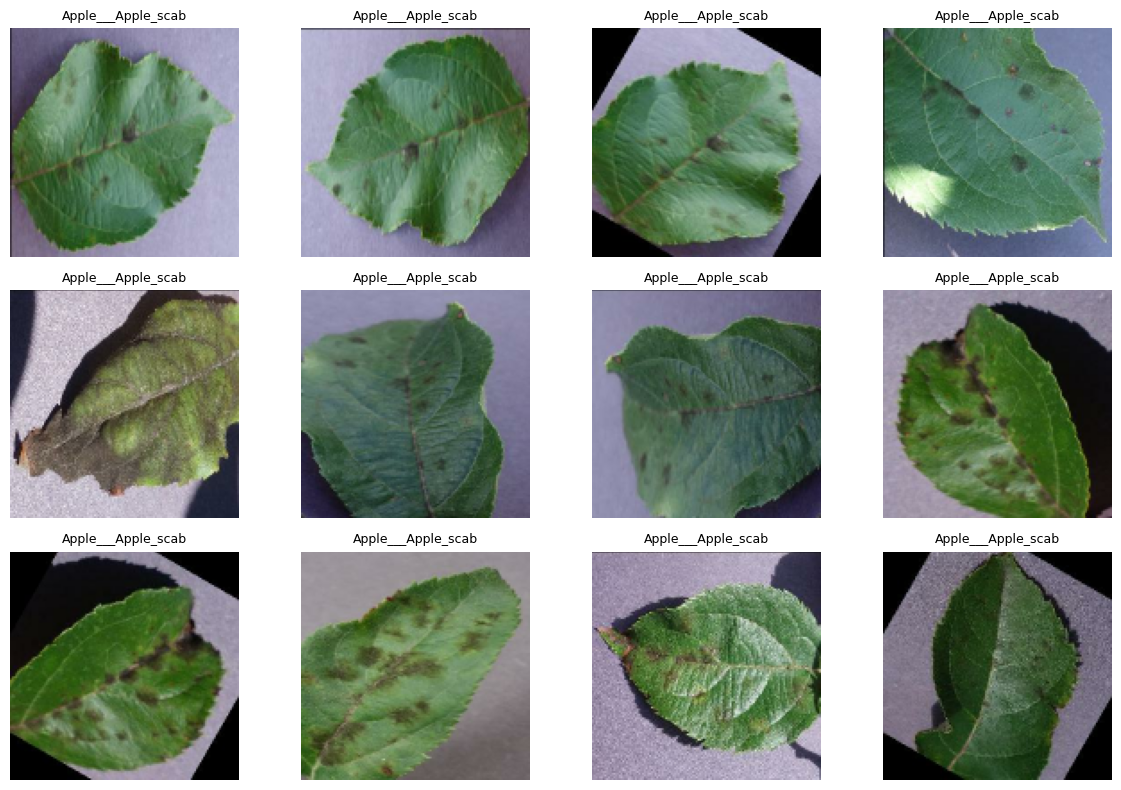

In [6]:
# %% 2) Show sample images with true labels
plt.figure(figsize=(12,8))
for images, labels in validation_set.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3,4,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true_idx = np.argmax(labels[i].numpy())
        plt.title(class_names[true_idx], fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()


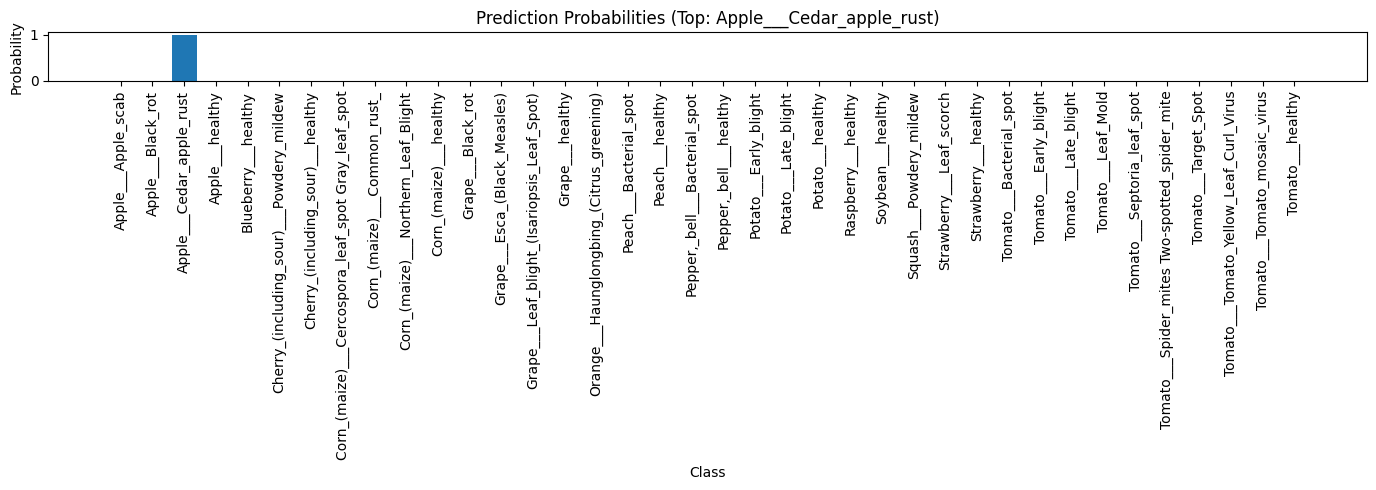

In [11]:
# %% 3) Single-image prediction probability bar chart
image_path = r'test\test\AppleCedarRust1.JPG'
image = tf.keras.preprocessing.image.load_img(image_path, target_size=(128,128))
input_arr = tf.keras.preprocessing.image.img_to_array(image)
input_arr = np.expand_dims(input_arr, axis=0)

pred = cnn.predict(input_arr, verbose=0)[0]
pred_idx = np.argmax(pred)

plt.figure(figsize=(14,5))
plt.bar(class_names, pred)
plt.title(f"Prediction Probabilities (Top: {class_names[pred_idx]})")
plt.xlabel("Class")
plt.ylabel("Probability")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


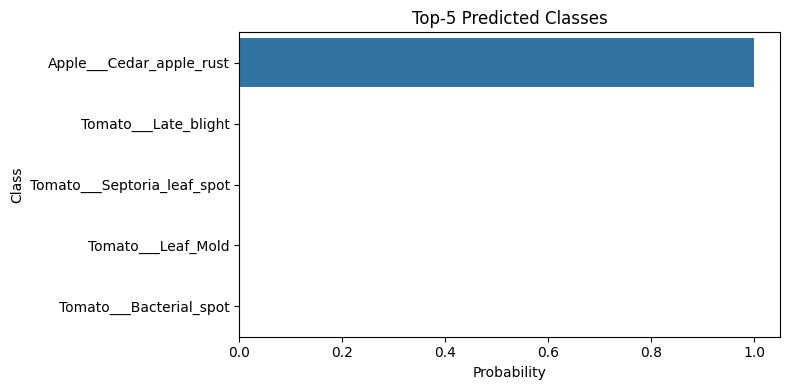

In [12]:
# %% 4) Top-5 probabilities for the test image
top5_idx = np.argsort(pred)[-5:][::-1]
top5_probs = pred[top5_idx]
top5_classes = [class_names[i] for i in top5_idx]

plt.figure(figsize=(8,4))
sns.barplot(x=top5_probs, y=top5_classes, orient='h')
plt.title("Top-5 Predicted Classes")
plt.xlabel("Probability")
plt.ylabel("Class")
plt.tight_layout()
plt.show()


In [9]:
# %% run before prediction cells
import tensorflow as tf

cnn = tf.keras.models.load_model('trained_plant_disease_model.keras')
print("Model loaded")


Model loaded


In [10]:
pred = cnn.predict(input_arr, verbose=0)[0]
import os
print(os.getcwd())
print(os.path.exists('trained_plant_disease_model.keras'))


c:\ai project vs code file\Plant_Disease_Dataset\Plant_Disease_Dataset
True


In [13]:
# %% 5) Confusion matrix (full validation set)
y_true, y_pred = [], []

for images, labels in validation_set:
    probs = cnn.predict(images, verbose=0)
    y_pred.extend(np.argmax(probs, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12,10))
sns.heatmap(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()


KeyboardInterrupt: 

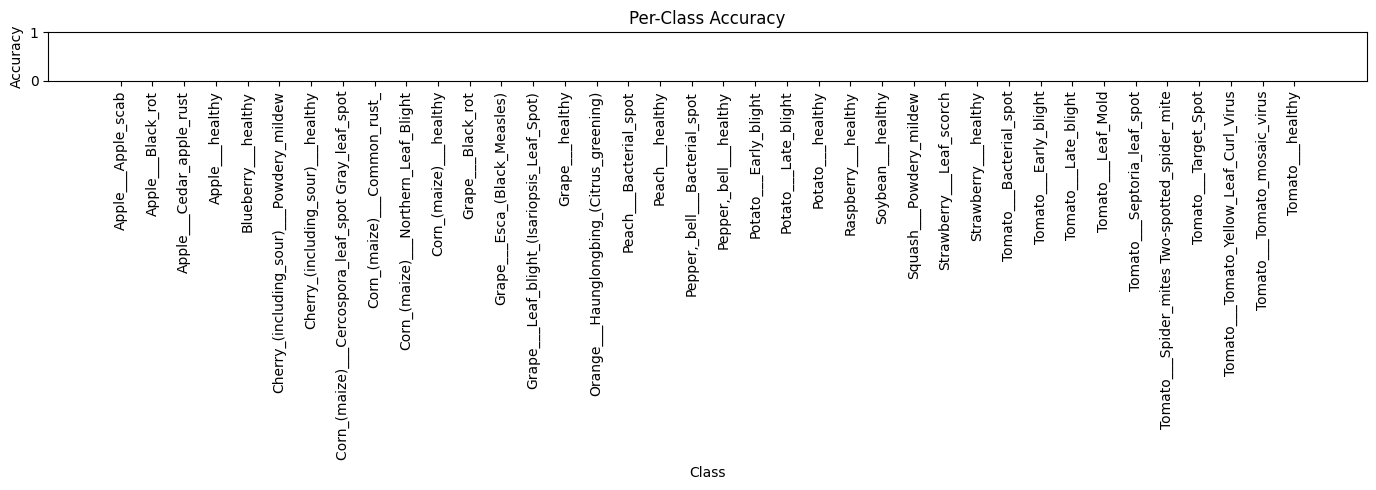

In [14]:
# %% 6) Per-class accuracy bar chart
class_acc = []
for i in range(len(class_names)):
    idx = np.where(y_true == i)[0]
    acc_i = (y_pred[idx] == i).mean() if len(idx) > 0 else 0
    class_acc.append(acc_i)

plt.figure(figsize=(14,5))
plt.bar(class_names, class_acc)
plt.title("Per-Class Accuracy")
plt.xlabel("Class")
plt.ylabel("Accuracy")
plt.ylim(0,1)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


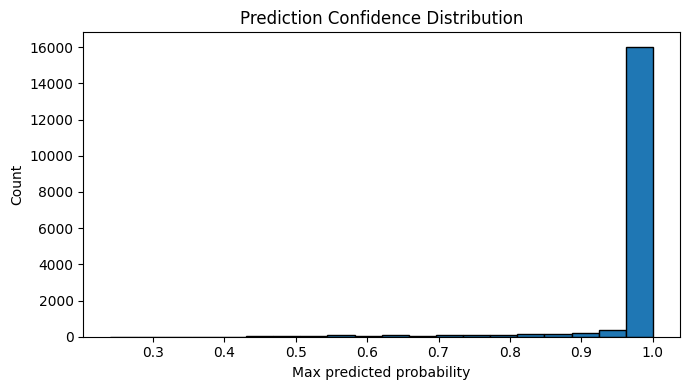

In [15]:
# %% 7) Confidence histogram (max probability)
# shows model confidence distribution on validation images
all_conf = []
for images, _ in validation_set:
    probs = cnn.predict(images, verbose=0)
    all_conf.extend(np.max(probs, axis=1))

plt.figure(figsize=(7,4))
plt.hist(all_conf, bins=20, edgecolor='black')
plt.title("Prediction Confidence Distribution")
plt.xlabel("Max predicted probability")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
